# Импорт

In [1]:
import sys
import os

In [2]:
# Добавление директории с модулями
module_dir = os.path.abspath("./my_scripts")

print(module_dir)

if module_dir not in sys.path:
    sys.path.append(module_dir)

d:\Projects\Python\Спринт_4_Preprocess\my_scripts


In [3]:
# Загрузка конфигурации
from my_scripts.config import Config

config = Config()

# Этап 1 Исследовательский анализ

In [4]:
from my_scripts.dataset import show_data_info

Размер словаря игредиентов: 200
Описательная статистика:
       total_calories   total_mass
count     3262.000000  3262.000000
mean       255.012738   214.980074
std        219.637570   161.497428
min          0.000000     1.000000
25%         80.114996    92.000000
50%        209.110062   177.000000
75%        375.122963   305.000000
max       3943.325195  3051.000000

Первые 10 строк
           dish_id  total_calories  total_mass  \
0  dish_1561662216      300.794281       193.0   
1  dish_1561662054      419.438782       292.0   
2  dish_1562008979      382.936646       290.0   
3  dish_1560455030       20.590000       103.0   
4  dish_1558372433       74.360001       143.0   
5  dish_1565640549       45.482903       139.0   
6  dish_1563207364      309.269989       271.0   
7  dish_1561575474      120.058434       183.0   
8  dish_1563216717      246.007996       332.0   
9  dish_1565972591      195.199997       122.0   

                                         ingredients  split 

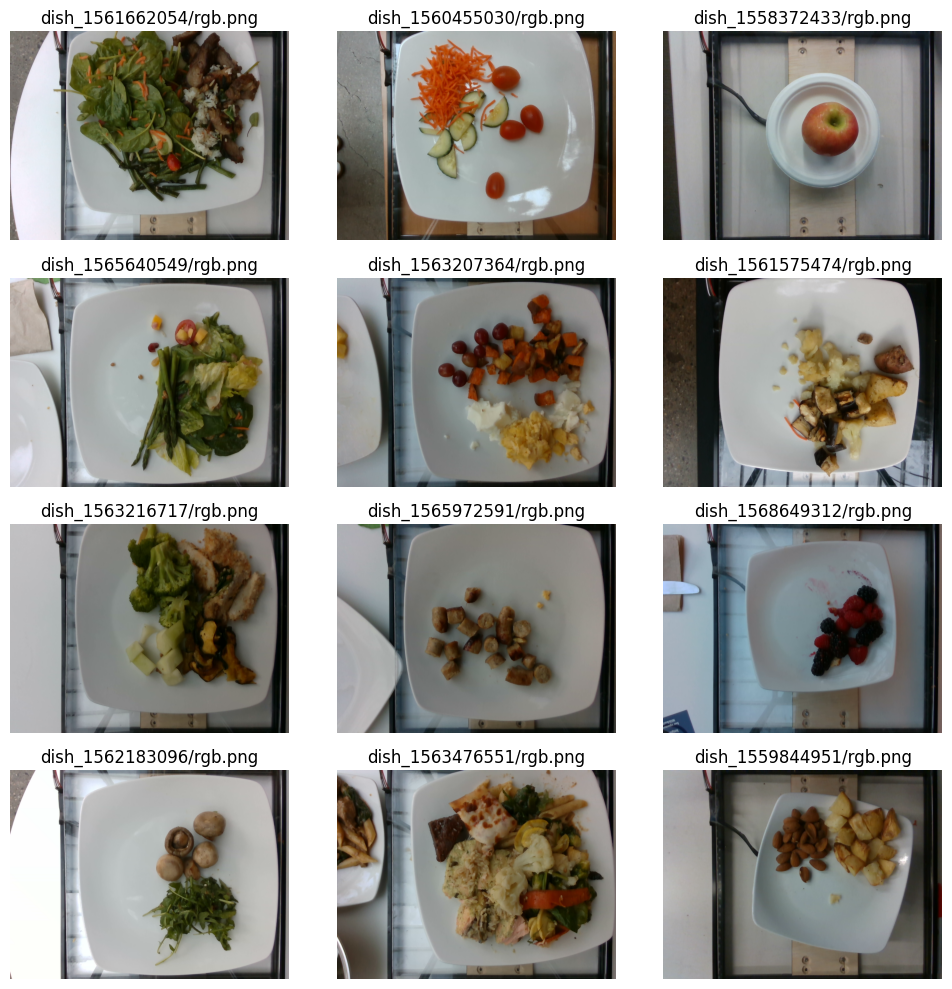

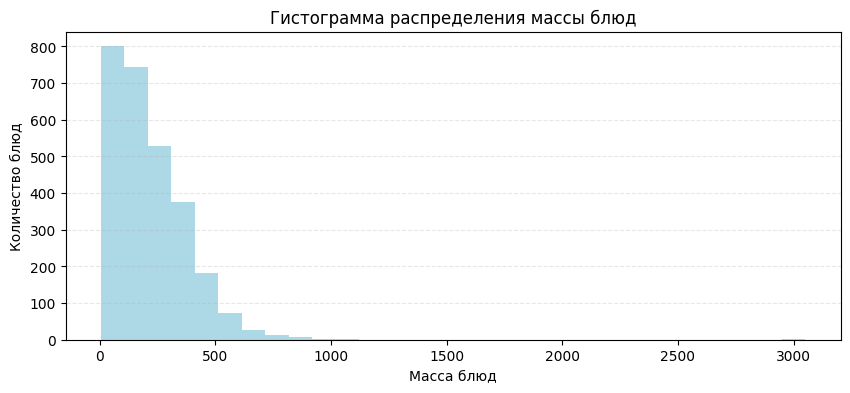

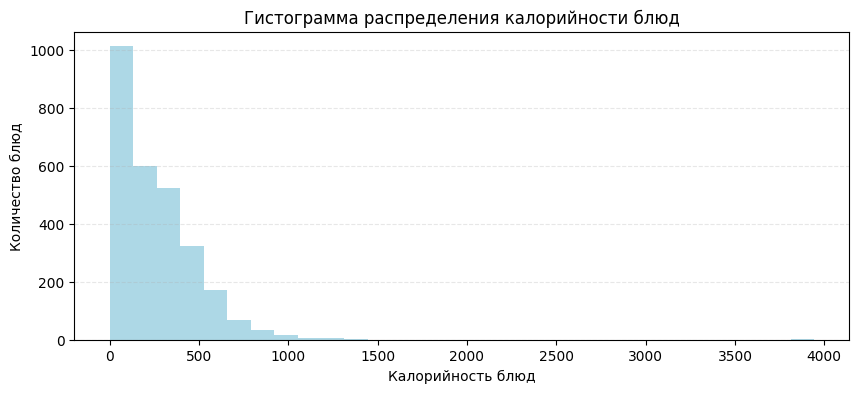

In [5]:
# Вывод информации о данных

show_data_info(config.ROOT_IMAGES_DIR, config.DISHES_FILE)

Уникальных ингредиентов, использованных в файле dishes.scv 200, при этом в файле ingedients.csv содержится 500.

# Этап 2. Пайплайн обучения

Тут особо писать нечего. Все в файлах dataset.py (загрузка данных и Dataset) и utils.py (Модель, обучение, расчет метрик, вывод информации).

# Этап 3. Обучение модели

In [113]:
%reload_ext autoreload
%autoreload 2

In [7]:
from my_scripts.utils import train

d:\Projects\Python\Спринт_4_Preprocess\env\lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Количество обучающих данных    :  2204
Количество валидационных данных:  551
Количество тестовых данных     :  507
Оценка средних и стандартных отклонений по каналам ...
Оценка средних и стандартных отклонений по каналам завершена.
mean:
(0.48904189467430115, 0.4718894064426422, 0.4388788044452667)
std:
(0.22391293942928314, 0.23774804174900055, 0.264164537191391)
Создание обучающего датасета


d:\Projects\Python\Спринт_4_Preprocess\env\lib\site-packages\torchvision\transforms\v2\_deprecated.py:42: UserWarning: The transform `ToTensor()` is deprecated and will be removed in a future release. Instead, please use `v2.Compose([v2.ToImage(), v2.ToDtype(torch.float32, scale=True)])`.Output is equivalent up to float precision.
  warnings.warn(
d:\Projects\Python\Спринт_4_Preprocess\my_scripts\dataset.py:205: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.detach().clone() or sourceTensor.detach().clone().requires_grad_(True), rather than torch.tensor(sourceTensor).
  self.total_calories = [torch.tensor(item) for item in total_calories]
d:\Projects\Python\Спринт_4_Preprocess\my_scripts\dataset.py:206: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.detach().clone() or sourceTensor.detach().clone().requires_grad_(True), rather than torch.tensor(sourceTensor).
  self.dish_structures = [torch.tensor(item) for item 

Продолжительность создания датасета:  0:00:00.390877
Создание валидационного датасета
Продолжительность создания датасета:  0:00:00.112967

Создание тестового датасета
Продолжительность создания датасета:  0:00:00.102971

Создание объектов DataLoader
Продолжительность создания объектов DataLoader:  0:00:00

train dataloader:  69
val   dataloader:  18
test  dataloader:  16
Количество параметров в модели калорийности: 14190889
> Эпоха 1


Validation: 100%|██████████| 18/18 [00:09<00:00,  1.96it/s]


Train Loss: 104093.39622961957, Val Loss: 60997.90234375, Best Val Loss 60997.90234375
Train MAE : 235.79348754882812, Val MAE : 173.95350646972656
> Эпоха 2


...

Train Loss: 3903.4186710965805, Val Loss: 7925.65185546875, Best Val Loss 5917.923828125
Train MAE : 40.74729919433594, Val MAE : 55.85798645019531
> Эпоха 100


Validation: 100%|██████████| 18/18 [00:02<00:00,  6.61it/s]


Train Loss: 3624.901749320652, Val Loss: 6078.38232421875, Best Val Loss 5917.923828125
Train MAE : 40.33040237426758, Val MAE : 51.951778411865234
Продолжительность обучения:  0:29:17.361949


Test      : 100%|██████████| 16/16 [00:15<00:00,  1.06it/s]


Test Loss 10453.61328125
Test MAE  67.75914001464844


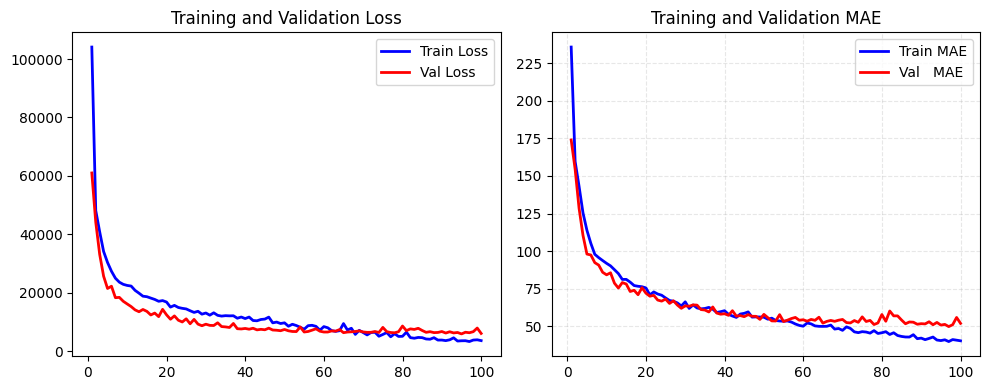

In [8]:
train(config=config)

Значения ошибки и MAE на тестовых и валидационных данных снижаются практически одновременно, и изменяются без сильных рывков. МAE на обучающих данных ниже, чем на валидационных и значение MAE < 50. 
К сожалению, значение MAE на тестовых данных составляет 67.759, что выше 50.

# Этап 4. Валидация качества

In [4]:
%reload_ext autoreload
%autoreload 2

При оценке модели я загружал лучшую из сохраненных моделей. При этом для нормализации изображений использовал mean и std, полученные для обучающих данных.

In [5]:
from my_scripts.utils import use_model

d:\Projects\Python\Спринт_4_Preprocess\env\lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


d:\Projects\Python\Спринт_4_Preprocess\env\lib\site-packages\torchvision\transforms\v2\_deprecated.py:42: UserWarning: The transform `ToTensor()` is deprecated and will be removed in a future release. Instead, please use `v2.Compose([v2.ToImage(), v2.ToDtype(torch.float32, scale=True)])`.Output is equivalent up to float precision.
  warnings.warn(
d:\Projects\Python\Спринт_4_Preprocess\my_scripts\dataset.py:205: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.detach().clone() or sourceTensor.detach().clone().requires_grad_(True), rather than torch.tensor(sourceTensor).
  self.total_calories = [torch.tensor(item) for item in total_calories]
d:\Projects\Python\Спринт_4_Preprocess\my_scripts\dataset.py:206: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.detach().clone() or sourceTensor.detach().clone().requires_grad_(True), rather than torch.tensor(sourceTensor).
  self.dish_structures = [torch.tensor(item) for item 


Модель:  models/best_multimodal_model.pth
Примеры расчета калорийности блюд: 
dish_1561662216/rgb.png: true calories = 300.794 predicted calories = 394.336
dish_1562008979/rgb.png: true calories = 382.937 predicted calories = 458.844
dish_1561739238/rgb.png: true calories = 274.190 predicted calories = 305.602
dish_1562691032/rgb.png: true calories = 419.682 predicted calories = 448.965
dish_1558549773/rgb.png: true calories = 2.300 predicted calories = 14.894

5 блюд с наибольшей ошибкой:
1. dish_1563221157/rgb.png: true calories = 418.152 predicted calories = 1065.635 absolute_error = 647.483
2. dish_1560526552/rgb.png: true calories = 359.241 predicted calories = 864.934 absolute_error = 505.693
3. dish_1563478751/rgb.png: true calories = 950.395 predicted calories = 495.933 absolute_error = 454.462
4. dish_1560526530/rgb.png: true calories = 245.281 predicted calories = 697.505 absolute_error = 452.224
5. dish_1566328805/rgb.png: true calories = 927.810 predicted calories = 521.54

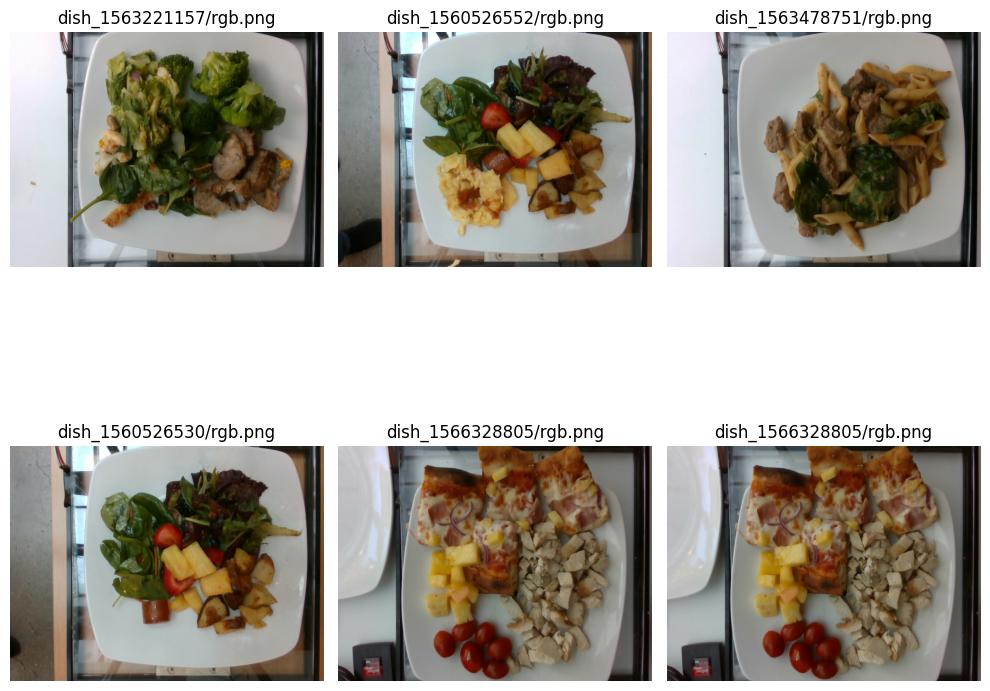

In [6]:
use_model(config=config)

# Выводы

Ошибка посчитана для всех блюд в тестовой выборке. 
По результатам расчета калорийности блюд (первые 5) видно, что модель все же ошибается незначительно. 

После сортировки блюд по убыванию ошибки и отображению результатов (в таблице и на картинках) видно, что модель сильно ошибается на блюдах, которые занимают почти всю тарелку. 

Возможно, что таких блюд не было в обучающих данных, и параметры нормализации данных их не учитывают.

Думаю, что нужно поработать с данными, возможно, перераспределить обучающие и тестовые, чтобы при тестировании не встречались совсем уж не похожие. В этом есть резон, так как человек кушает еду, а не "непонятно что".

Я бы использовал модель. +/- 100 ккалорий - нестрашо. То на то и выйдет.